In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, roc_curve
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
path="/content/drive/MyDrive/Dataset/E-commerce Shipping Dataset.csv"
df=pd.read_csv(path)
df.head(20)

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1
5,6,F,Flight,3,1,162,3,medium,F,12,1417,1
6,7,D,Flight,3,4,250,3,low,F,3,2371,1
7,8,F,Flight,4,1,233,2,low,F,48,2804,1
8,9,A,Flight,3,4,150,3,low,F,11,1861,1
9,10,B,Flight,3,2,164,3,medium,F,29,1187,1


# **EDA**



In [ ]:
df.shape

(10999, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   10999 non-null  int64 
 1   Warehouse_block      10999 non-null  object
 2   Mode_of_Shipment     10999 non-null  object
 3   Customer_care_calls  10999 non-null  int64 
 4   Customer_rating      10999 non-null  int64 
 5   Cost_of_the_Product  10999 non-null  int64 
 6   Prior_purchases      10999 non-null  int64 
 7   Product_importance   10999 non-null  object
 8   Gender               10999 non-null  object
 9   Discount_offered     10999 non-null  int64 
 10  Weight_in_gms        10999 non-null  int64 
 11  Reached.on.Time_Y.N  10999 non-null  int64 
dtypes: int64(8), object(4)
memory usage: 1.0+ MB


In [ ]:
df.describe()

,ID,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
count,10999.00000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000
mean,5500.00000,4.054459,2.990545,210.196836,3.567597,13.373216,3634.016729,0.596691
std,3175.28214,1.141490,1.413603,48.063272,1.522860,16.205527,1635.377251,0.490584
min,1.00000,2.000000,1.000000,96.000000,2.000000,1.000000,1001.000000,0.000000
25%,2750.50000,3.000000,2.000000,169.000000,3.000000,4.000000,1839.500000,0.000000
50%,5500.00000,4.000000,3.000000,214.000000,3.000000,7.000000,4149.000000,1.000000
75%,8249.50000,5.000000,4.000000,251.000000,4.000000,10.000000,5050.000000,1.000000
max,10999.00000,7.000000,5.000000,310.000000,10.000000,65.000000,7846.000000,1.000000


**Numerical features**


In [ ]:
#numerical features

numerical_data = df.select_dtypes(include = 'number')

numerical_features = numerical_data.columns.tolist()

print(f"There are {len(numerical_features)} amount of numerical features.\n")
print(f"They are: {numerical_features}")

There are 8 amount of numerical features.

They are: ['ID', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms', 'Reached.on.Time_Y.N']


Categorical Features

In [ ]:
#categorical features

categorical_data = df.select_dtypes(include = 'object')

categorical_features = categorical_data.columns.tolist()

print(f"There are {len(categorical_features)} amount of categorical features.\n")
print(f"They are: {categorical_features}")

There are 4 amount of categorical features.

They are: ['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']


# **Summary of Numerical Data**

In [ ]:
numerical_data.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,10999.0,5500.000000,3175.282140,1.0,2750.5,5500.0,8249.5,10999.0
Customer_care_calls,10999.0,4.054459,1.141490,2.0,3.0,4.0,5.0,7.0
Customer_rating,10999.0,2.990545,1.413603,1.0,2.0,3.0,4.0,5.0
Cost_of_the_Product,10999.0,210.196836,48.063272,96.0,169.0,214.0,251.0,310.0
Prior_purchases,10999.0,3.567597,1.522860,2.0,3.0,3.0,4.0,10.0
Discount_offered,10999.0,13.373216,16.205527,1.0,4.0,7.0,10.0,65.0
Weight_in_gms,10999.0,3634.016729,1635.377251,1001.0,1839.5,4149.0,5050.0,7846.0
Reached.on.Time_Y.N,10999.0,0.596691,0.490584,0.0,0.0,1.0,1.0,1.0


# **Summary of Categorical Data**

In [ ]:
categorical_data.describe().T

,count,unique,top,freq
Warehouse_block,10999,5,F,3666
Mode_of_Shipment,10999,3,Ship,7462
Product_importance,10999,3,low,5297
Gender,10999,2,F,5545


# **Variance and Skewness of Numerical Data**

In [ ]:
numerical_data.var()

,0
ID,1.008242e+07
Customer_care_calls,1.302999e+00
Customer_rating,1.998274e+00
Cost_of_the_Product,2.310078e+03
Prior_purchases,2.319103e+00
Discount_offered,2.626191e+02
Weight_in_gms,2.674459e+06
Reached.on.Time_Y.N,2.406728e-01


In [ ]:
numerical_data.skew()

,0
ID,0.000000
Customer_care_calls,0.391926
Customer_rating,0.004360
Cost_of_the_Product,-0.157117
Prior_purchases,1.681897
Discount_offered,1.798929
Weight_in_gms,-0.249747
Reached.on.Time_Y.N,-0.394257


In [ ]:
#Number of unique values in the numerical dataset
numerical_data.nunique()

,0
ID,10999
Customer_care_calls,6
Customer_rating,5
Cost_of_the_Product,215
Prior_purchases,8
Discount_offered,65
Weight_in_gms,4034
Reached.on.Time_Y.N,2


# **Boxplots and Histograms**

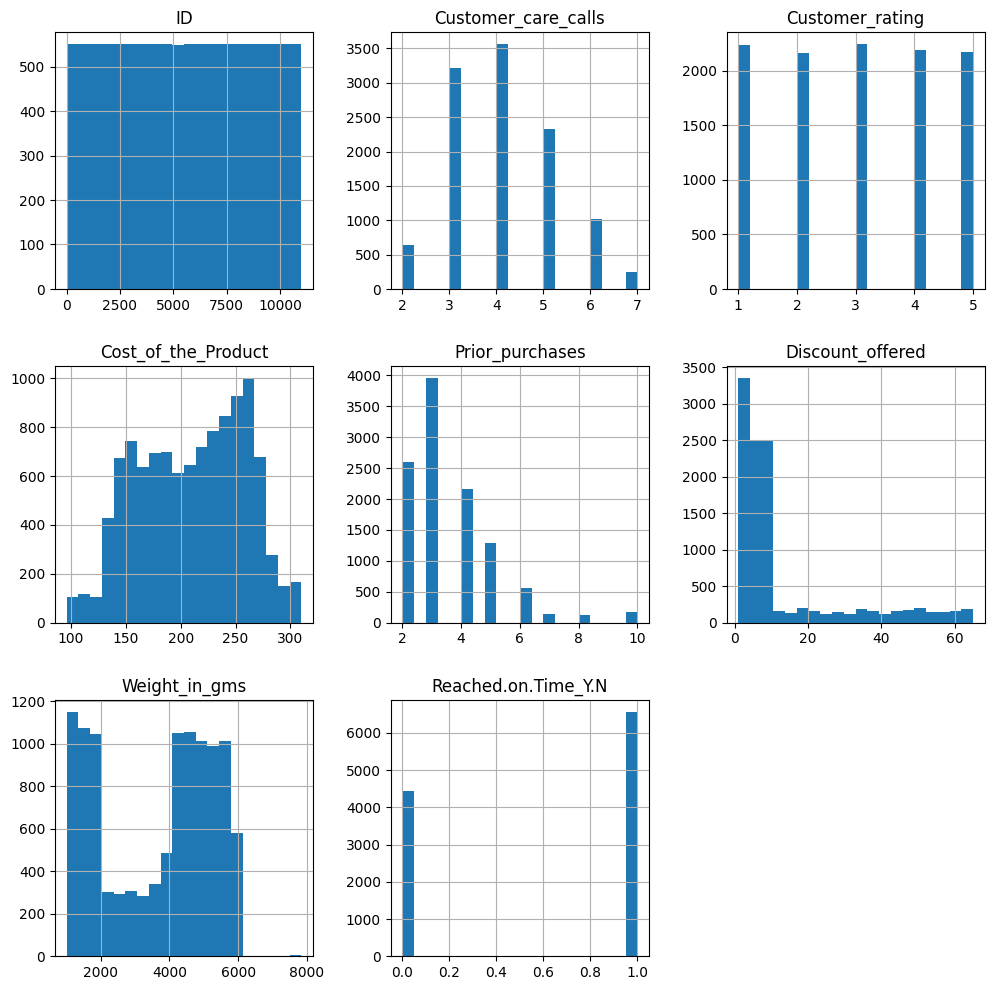

In [ ]:
numerical_data.hist(figsize = (12, 12), bins = 20)
plt.show()

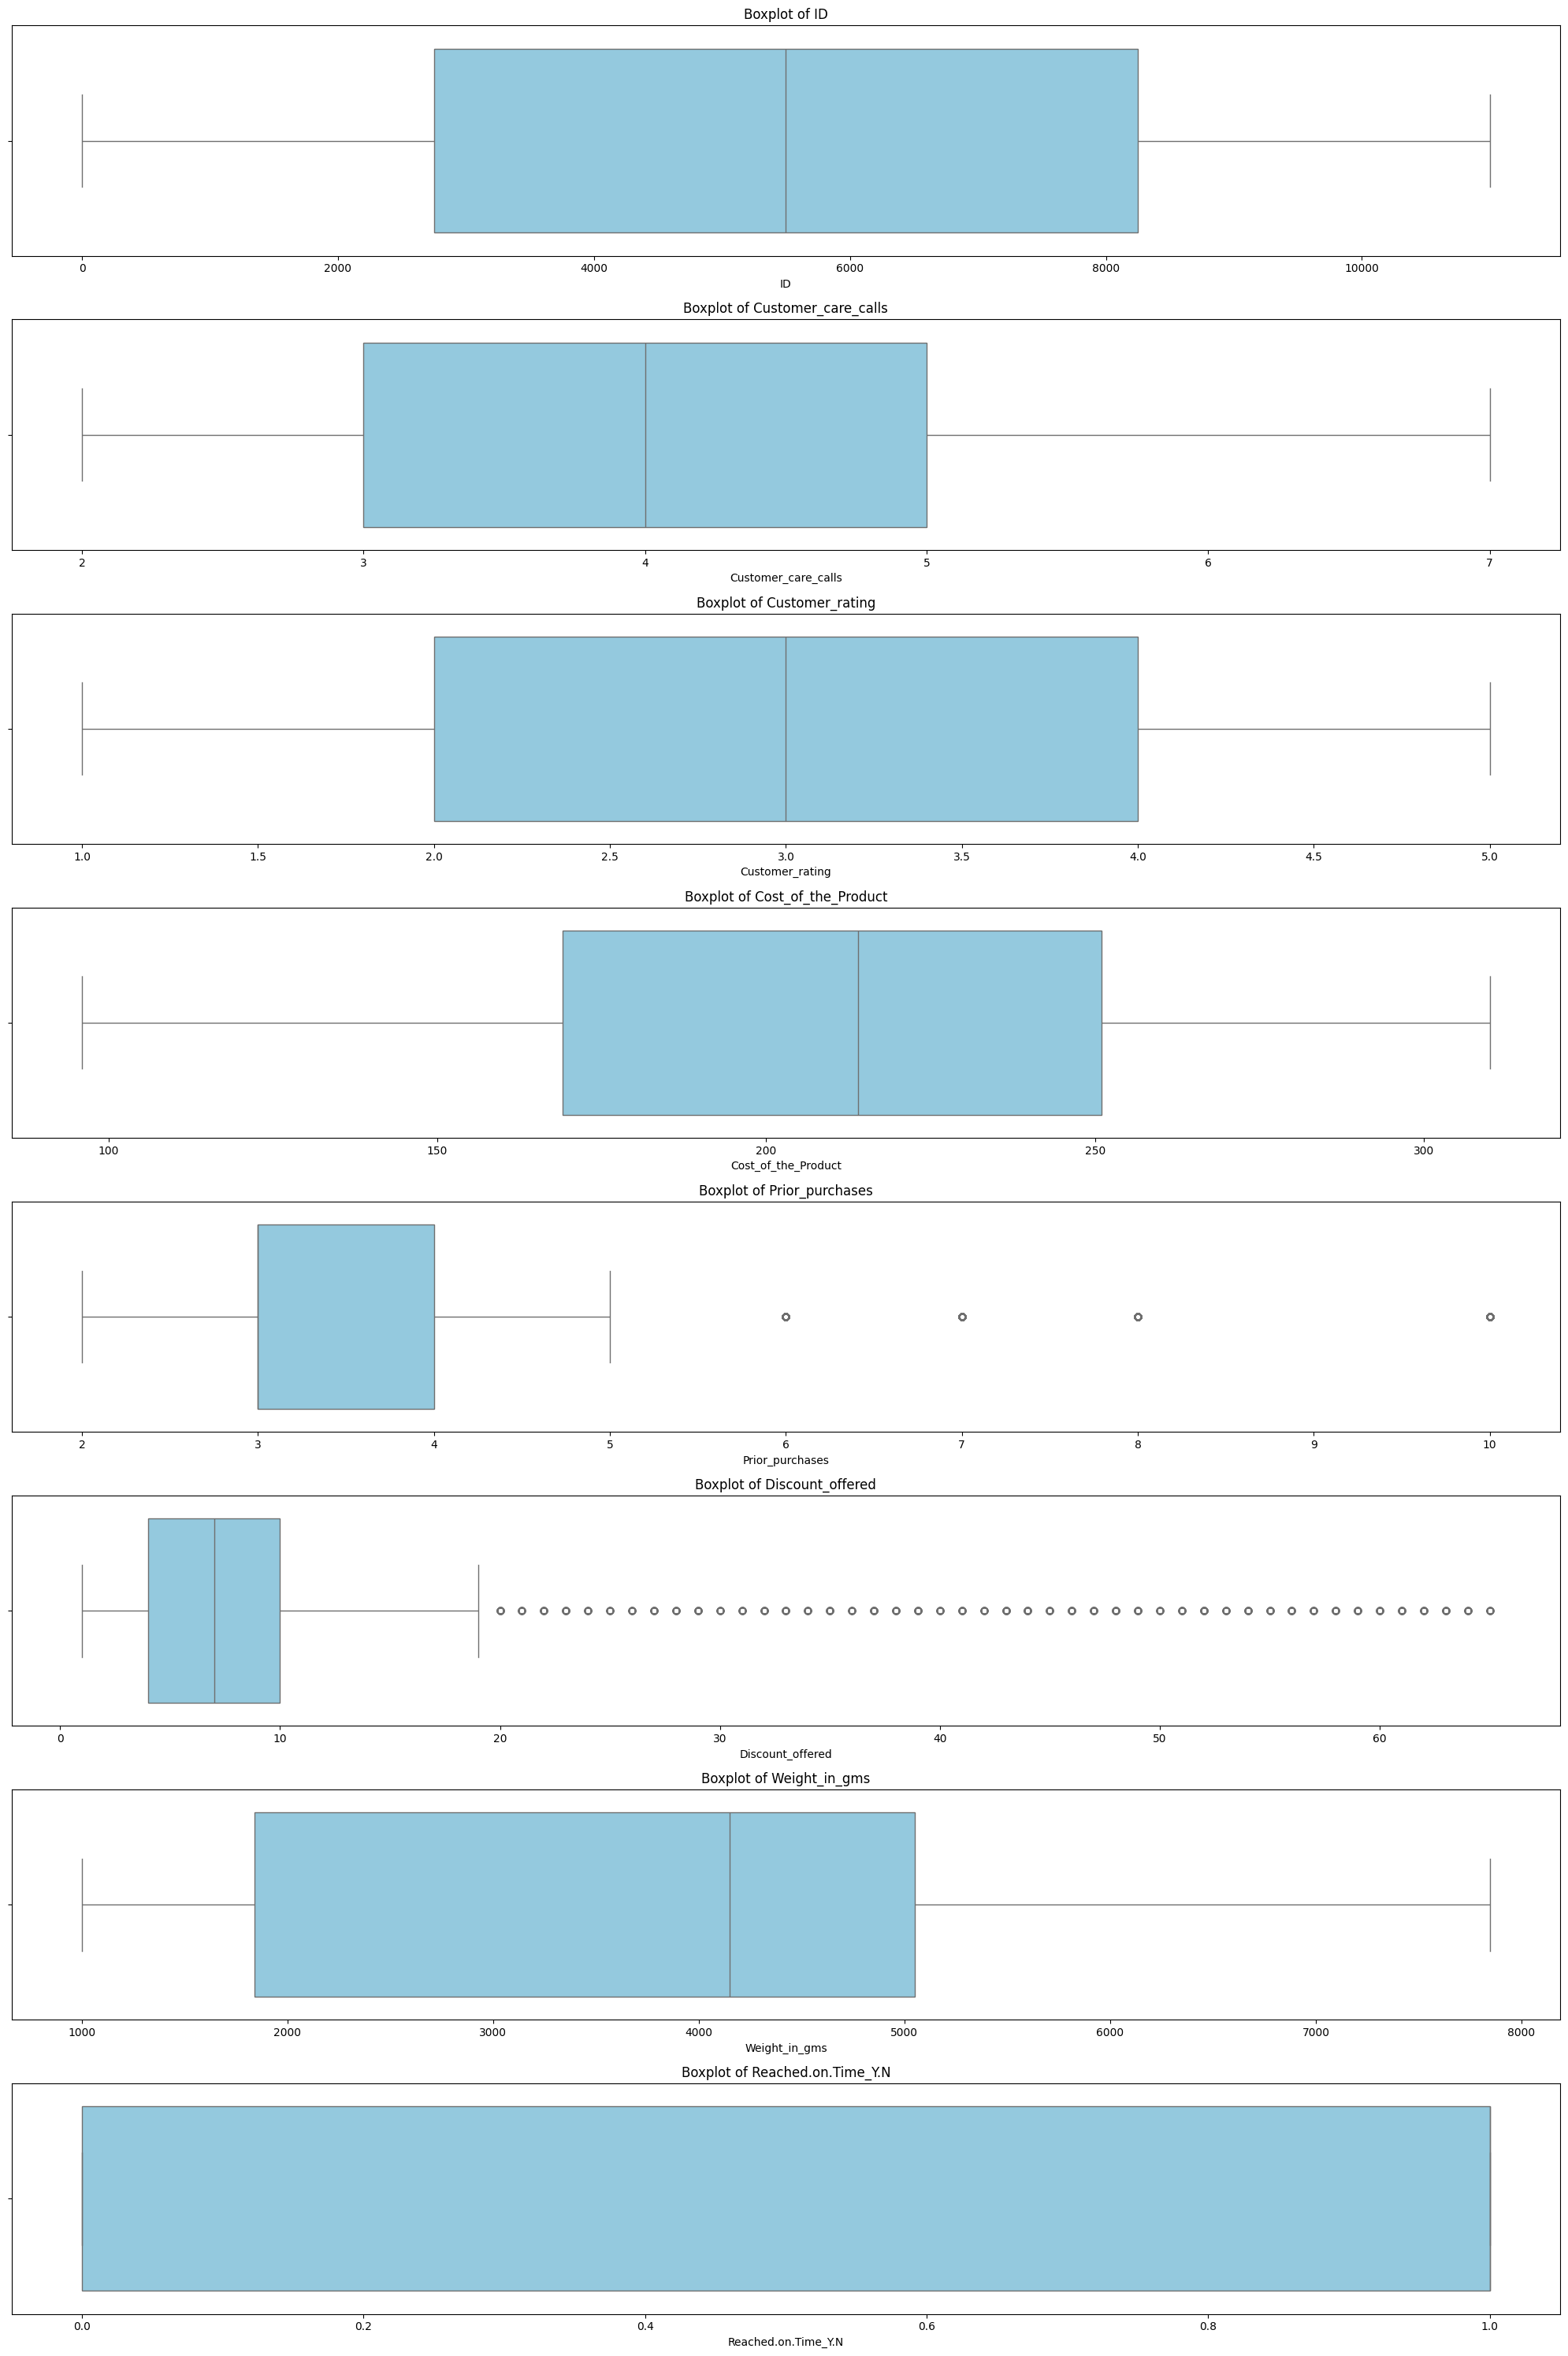

In [ ]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

plt.figure(figsize=(20, 30))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols), 1, i)
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontsize=12)
    plt.tight_layout()

plt.show()

# **Number Unique values in each feature**


In [ ]:
numerical_data.nunique()

,0
ID,10999
Customer_care_calls,6
Customer_rating,5
Cost_of_the_Product,215
Prior_purchases,8
Discount_offered,65
Weight_in_gms,4034
Reached.on.Time_Y.N,2


# **Missing Values**

In [ ]:
numerical_data.isnull().sum()

,0
ID,0
Customer_care_calls,0
Customer_rating,0
Cost_of_the_Product,0
Prior_purchases,0
Discount_offered,0
Weight_in_gms,0
Reached.on.Time_Y.N,0


# **Categorical Features**

# **Number of unique values in the categorical dataset**

In [ ]:
categorical_counts = categorical_data.nunique()
categorical_counts

,0
Warehouse_block,5
Mode_of_Shipment,3
Product_importance,3
Gender,2


# **Barplot of unique value counts in every categorical features**

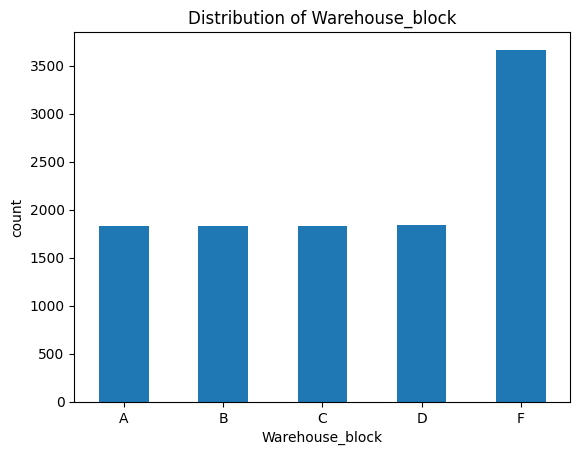

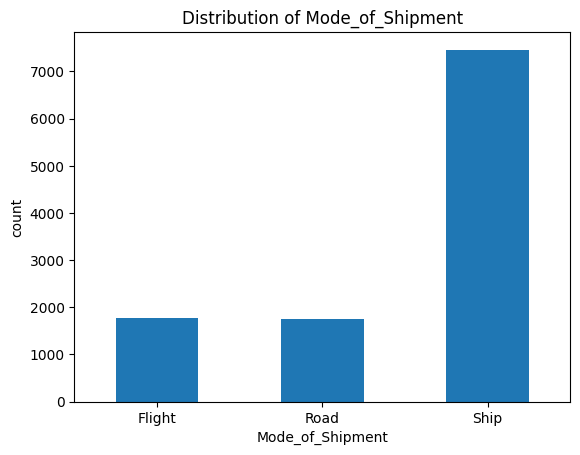

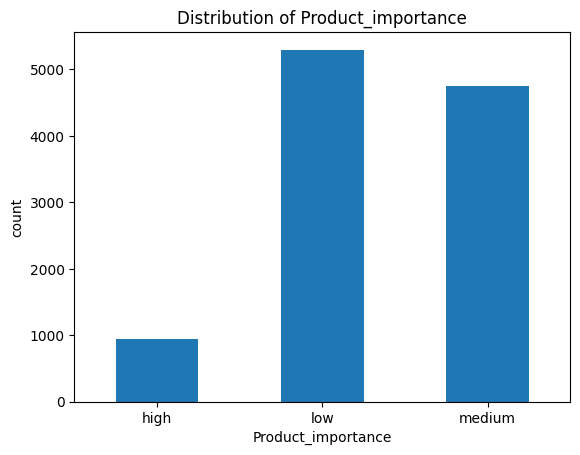

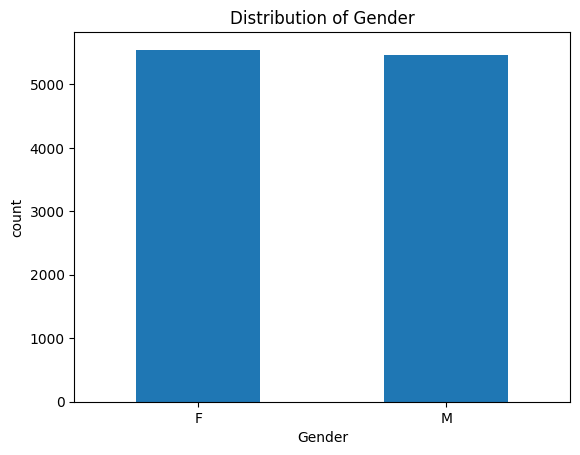

In [ ]:
for col in categorical_features:
    plt.title(f'Distribution of {col}')
    categorical_data[col].value_counts().sort_index().plot(kind='bar', rot=0, xlabel=col,ylabel='count')
    plt.show()

# **Correlation Analysis**

# **Correlation matrix of whole dataset**

In [ ]:
correlation_matrix = numerical_data.corr()
correlation_matrix

,ID,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
ID,1.000000,0.188998,-0.005722,0.196791,0.145369,-0.598278,0.278312,-0.411822
Customer_care_calls,0.188998,1.000000,0.012209,0.323182,0.180771,-0.130750,-0.276615,-0.067126
Customer_rating,-0.005722,0.012209,1.000000,0.009270,0.013179,-0.003124,-0.001897,0.013119
Cost_of_the_Product,0.196791,0.323182,0.009270,1.000000,0.123676,-0.138312,-0.132604,-0.073587
Prior_purchases,0.145369,0.180771,0.013179,0.123676,1.000000,-0.082769,-0.168213,-0.055515
Discount_offered,-0.598278,-0.130750,-0.003124,-0.138312,-0.082769,1.000000,-0.376067,0.397108
Weight_in_gms,0.278312,-0.276615,-0.001897,-0.132604,-0.168213,-0.376067,1.000000,-0.268793
Reached.on.Time_Y.N,-0.411822,-0.067126,0.013119,-0.073587,-0.055515,0.397108,-0.268793,1.000000


# **Correlation Heatmap plot of whole dataset**

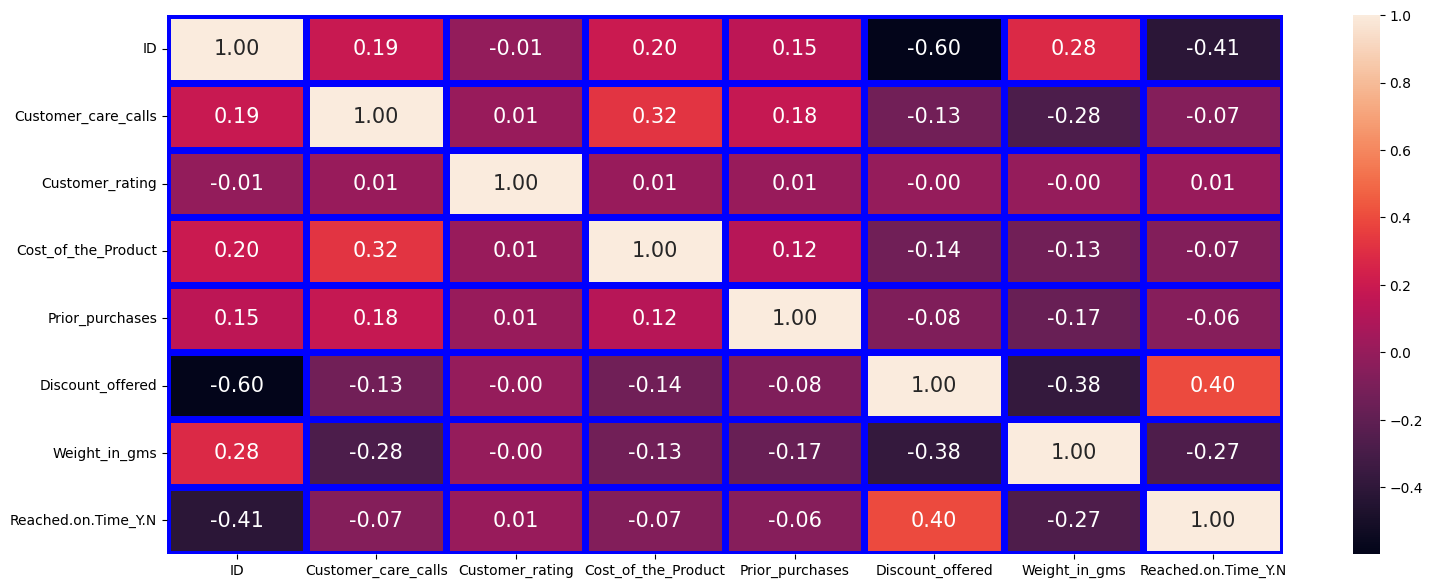

In [ ]:
plt.figure(figsize = (18, 7))
sns.heatmap(df.corr(numeric_only=True), annot = True, fmt = '0.2f', annot_kws = {'size' : 15}, linewidth = 5, linecolor = 'blue')
plt.show()

In [ ]:
df.head(5)

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


# **Co-Relation between customer care calls, customer ratings and gender**

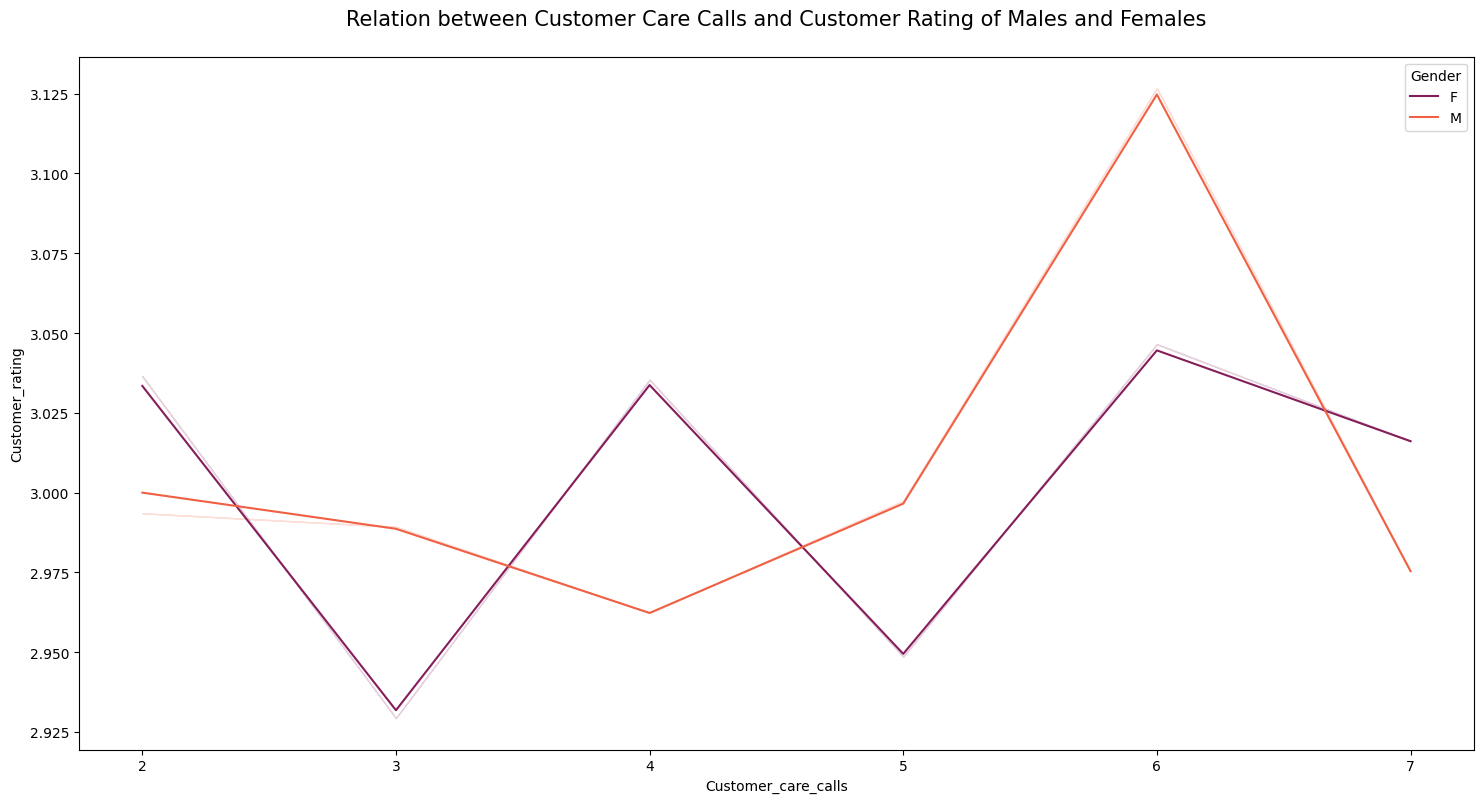

In [ ]:
plt.figure(figsize = (18, 9))
sns.lineplot(x = 'Customer_care_calls', y = 'Customer_rating', hue = 'Gender', data = df,
             palette = 'rocket', errorbar=('ci', 0))
plt.title('Relation between Customer Care Calls and Customer Rating of Males and Females\n',
          fontsize = 15)
plt.show()

# **Correlation Matrix of numerical Features**

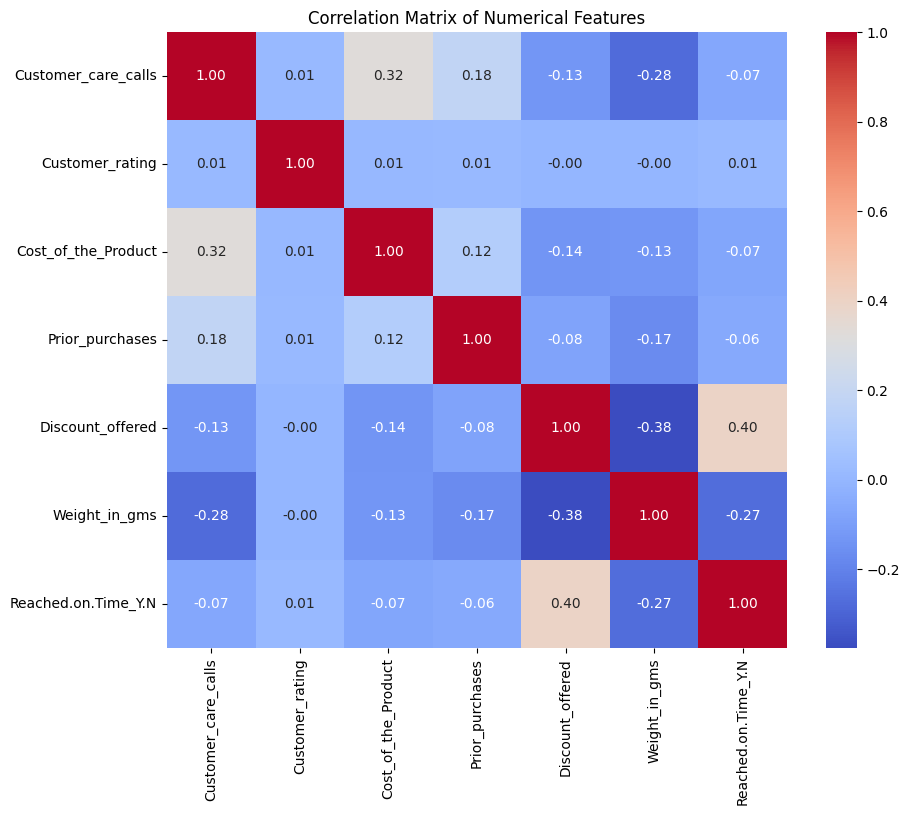

In [ ]:
numerical_df = df.select_dtypes(include=['number'])

if 'ID' in numerical_df.columns:
    numerical_df = numerical_df.drop(columns=['ID'])

correlation_matrix = numerical_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Features')
plt.show()

# **Imbalanced Dataset Analysis**

/tmp/ipython-input-149099494.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=target_col, data=df, palette='viridis')


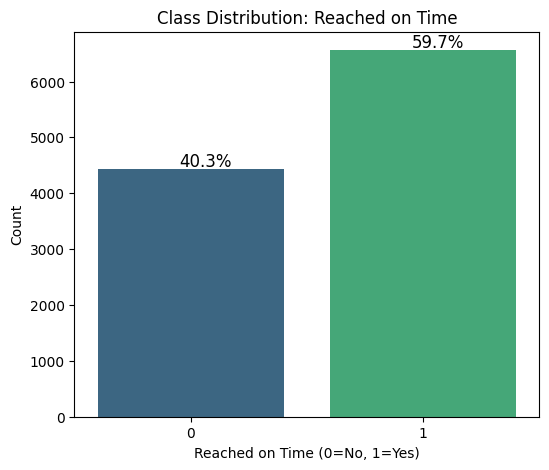

In [ ]:
target_col = 'Reached.on.Time_Y.N'
counts = df[target_col].value_counts()
percentages = df[target_col].value_counts(normalize=True) * 100


plt.figure(figsize=(6, 5))
sns.countplot(x=target_col, data=df, palette='viridis')
plt.title('Class Distribution: Reached on Time')
plt.xlabel('Reached on Time (0=No, 1=Yes)')
plt.ylabel('Count')

total = len(df)
ax = plt.gca()
for p in ax.patches:
    percentage = '{:.1f}%'.format(100 * p.get_height()/total)
    x = p.get_x() + p.get_width() / 2 - 0.05
    y = p.get_height() + 50
    ax.annotate(percentage, (x, y), size=12)

plt.show()

# **Pre-Processing**

# **Nulls & Irrelevant Data**

In [ ]:
missing_values = df.isnull().sum()
print(f"Missing Values before fix:\n{missing_values[missing_values > 0]}")

if 'ID' in df.columns:
    df.drop(columns=['ID'], inplace=True)
    print("Action: Dropped 'ID' column.")

print("Data shape after dropping ID:", df.shape)

Missing Values before fix:
Series([], dtype: int64)
Action: Dropped 'ID' column.
Data shape after dropping ID: (10999, 11)


# **Encoding Categorical Values**

In [ ]:
importance_map = {'low': 0, 'medium': 1, 'high': 2}
df['Product_importance'] = df['Product_importance'].map(importance_map)
print("Action: Mapped 'Product_importance' to 0, 1, 2.")

le = LabelEncoder()
df['Gender'] = le.fit_transform(df['Gender'])
print("Action: Label Encoded 'Gender' (0=F, 1=M).")

df = pd.get_dummies(df, columns=['Warehouse_block', 'Mode_of_Shipment'], drop_first=True)
print("Action: One-Hot Encoded 'Warehouse_block' and 'Mode_of_Shipment'.")

print(df.head())

Action: Mapped 'Product_importance' to 0, 1, 2.
Action: Label Encoded 'Gender' (0=F, 1=M).
Action: One-Hot Encoded 'Warehouse_block' and 'Mode_of_Shipment'.
   Customer_care_calls  Customer_rating  Cost_of_the_Product  Prior_purchases  \
0                    4                2                  177                3   
1                    4                5                  216                2   
2                    2                2                  183                4   
3                    3                3                  176                4   
4                    2                2                  184                3   

   Product_importance  Gender  Discount_offered  Weight_in_gms  \
0                   0       0                44           1233   
1                   0       1                59           3088   
2                   0       1                48           3374   
3                   1       1                10           1177   
4                   1     

# **Feature Scaling**

In [ ]:
scaler = StandardScaler()

cols_to_scale = ['Cost_of_the_Product', 'Discount_offered', 'Weight_in_gms',
                 'Customer_care_calls', 'Customer_rating', 'Prior_purchases']

df[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])

print(f"Action: Scaled columns: {cols_to_scale}")
print("\nFinal Data Preview:")
print(df.head())

Action: Scaled columns: ['Cost_of_the_Product', 'Discount_offered', 'Weight_in_gms', 'Customer_care_calls', 'Customer_rating', 'Prior_purchases']

Final Data Preview:
   Customer_care_calls  Customer_rating  Cost_of_the_Product  Prior_purchases  \
0            -0.047711        -0.700755            -0.690722        -0.372735   
1            -0.047711         1.421578             0.120746        -1.029424   
2            -1.799887        -0.700755            -0.565881         0.283954   
3            -0.923799         0.006689            -0.711529         0.283954   
4            -1.799887        -0.700755            -0.545074        -0.372735   

   Product_importance  Gender  Discount_offered  Weight_in_gms  \
0                   0       0          1.889983      -1.468240   
1                   0       1          2.815636      -0.333893   
2                   0       1          2.136824      -0.159002   
3                   1       1         -0.208162      -1.502484   
4               

In [ ]:
target_col = 'Reached.on.Time_Y.N'

X = df.drop(columns=[target_col])
y = df[target_col]


# **Data Splitting**

# **Features (X) and Target (y)**

In [ ]:

X = df.drop('Reached.on.Time_Y.N', axis=1)


y = df['Reached.on.Time_Y.N']

print("Features (X) and Target (y) defined.")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

Features (X) and Target (y) defined.
X shape: (10999, 14)
y shape: (10999,)


# **80% Train, 20% Test**

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Data successfully split into Train and Test sets.")
print("Training Set Shape:", X_train.shape)
print("Testing Set Shape: ", X_test.shape)
print("\n--- Class Balance Check (Percentage) ---")
print(f"Original Data:\n{y.value_counts(normalize=True)}\n")
print(f"Training Set:\n{y_train.value_counts(normalize=True)}\n")
print(f"Testing Set:\n{y_test.value_counts(normalize=True)}\n")

Data successfully split into Train and Test sets.
Training Set Shape: (8799, 14)
Testing Set Shape:  (2200, 14)

--- Class Balance Check (Percentage) ---
Original Data:
Reached.on.Time_Y.N
1    0.596691
0    0.403309
Name: proportion, dtype: float64

Training Set:
Reached.on.Time_Y.N
1    0.596659
0    0.403341
Name: proportion, dtype: float64

Testing Set:
Reached.on.Time_Y.N
1    0.596818
0    0.403182
Name: proportion, dtype: float64



# **Model Training**

In [ ]:
# 1. Decision Tree

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
print("1. Decision Tree: Trained successfully.")

# 2. Logistic Regression

lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train, y_train)
print("2. Logistic Regression: Trained successfully.")

# 3. Neural Network (MLPClassifier)
nn_model = MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42)
nn_model.fit(X_train, y_train)
print("3. Neural Network: Trained successfully.")

1. Decision Tree: Trained successfully.
2. Logistic Regression: Trained successfully.
3. Neural Network: Trained successfully.


# **Unsupervised Learning (K-Means)**

K-Means clustering applied. Cluster labels assigned to dataset.


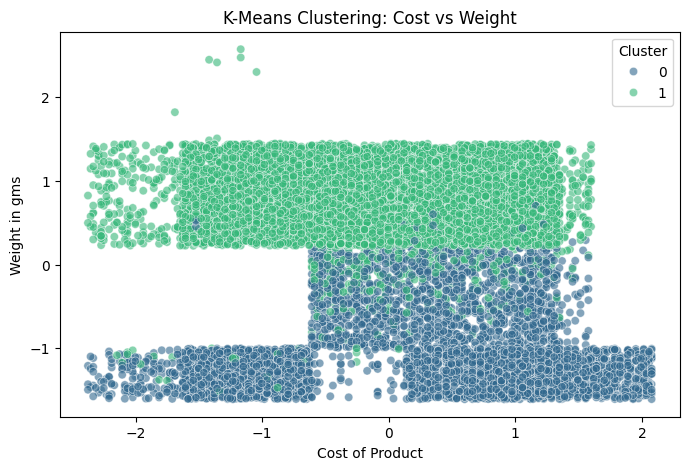

In [ ]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans.fit(X)

df['Cluster_Label'] = kmeans.labels_
print("K-Means clustering applied. Cluster labels assigned to dataset.")

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Cost_of_the_Product', y='Weight_in_gms', hue='Cluster_Label', palette='viridis', alpha=0.6)
plt.title('K-Means Clustering: Cost vs Weight')
plt.xlabel('Cost of Product')
plt.ylabel('Weight in gms')
plt.legend(title='Cluster')
plt.show()

# **Model Selection & Comparison**

In [ ]:
models = {
    'Decision Tree': dt_model,
    'Logistic Regression': lr_model,
    'Neural Network': nn_model
}

results = []



for name, model in models.items():
    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)


    results.append([name, acc, prec, rec, f1, auc])

results_df = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC Score'])
results_df.set_index('Model', inplace=True)

print(results_df)

                     Accuracy  Precision    Recall  F1 Score  AUC Score
Model                                                                  
Decision Tree        0.635000   0.692308  0.699162  0.695718   0.619592
Logistic Regression  0.640000   0.708567  0.674029  0.690867   0.717445
Neural Network       0.630455   0.664258  0.769992  0.713228   0.726619


# **Visualizations**

/tmp/ipython-input-2060674226.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.index, y=results_df['Accuracy'], palette='viridis')


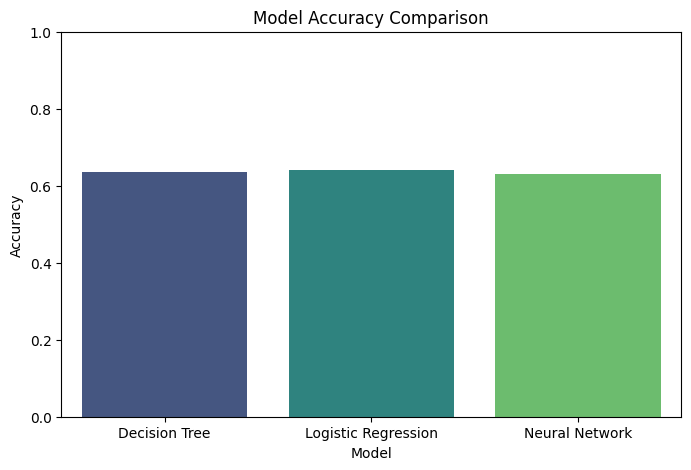

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(x=results_df.index, y=results_df['Accuracy'], palette='viridis')
plt.title('Model Accuracy Comparison')
plt.ylim(0, 1)
plt.ylabel('Accuracy')
plt.show()







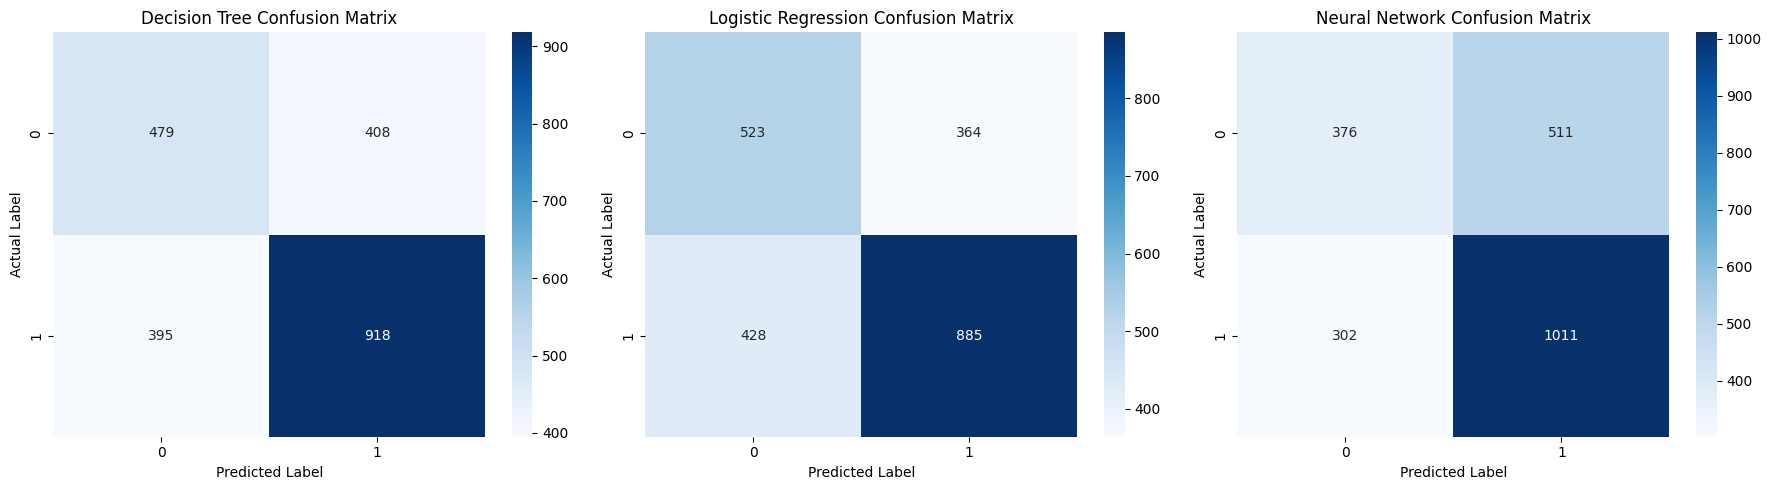

In [ ]:
# 2. Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)


    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(f'{name} Confusion Matrix')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

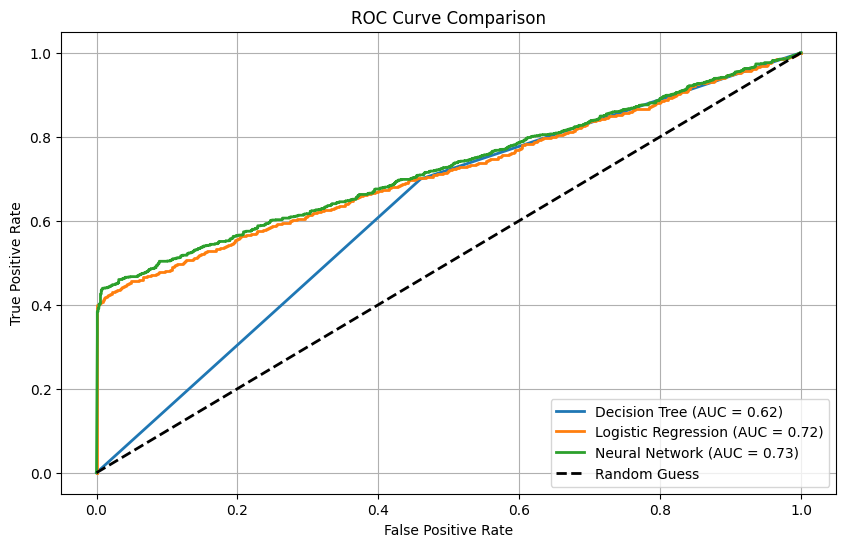

In [ ]:
# 3. ROC Curves
plt.figure(figsize=(10, 6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)

    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {results_df.loc[name, "AUC Score"]:.2f})')


plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Guess')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [ ]:

results_df_sorted = results_df.sort_values(by='Accuracy', ascending=False)

print(results_df_sorted)
best_model_name = results_df_sorted.index[0]
best_acc = results_df_sorted.iloc[0]['Accuracy']
print(f"\nThe Best Model is: {best_model_name} with {best_acc:.2%} Accuracy.")

                     Accuracy  Precision    Recall  F1 Score  AUC Score
Model                                                                  
Logistic Regression  0.640000   0.708567  0.674029  0.690867   0.717445
Decision Tree        0.635000   0.692308  0.699162  0.695718   0.619592
Neural Network       0.630455   0.664258  0.769992  0.713228   0.726619

The Best Model is: Logistic Regression with 64.00% Accuracy.
